# Projet NEAT : sauver l'équilibre du monde

## Mission

L'Agence spatiale européenne et les spécialistes mondiaux du contrôle automatique ont échoué à résoudre un problème apparemment simple : maintenir un ou plusieurs pendules sur un chariot, en position verticale, malgré la gravité. Le destin du monde dépend désormais de vous.

Les meilleures solutions actuellement disponibles sont les **contrôleurs naïfs** présentés dans ce notebook. Ils constituent une référence minimale, mais ils ne suffisent pas pour résoudre toutes les situations. Votre mission est de concevoir, entraîner et analyser des contrôleurs capables d'équilibrer ces systèmes grâce à **NEAT** (*NeuroEvolution of Augmenting Topologies*).

Les TPs consacrés à NEAT sont disponibles pour vous aider à implémenter l'algorithme. Vous pouvez réutiliser le code développé pendant ces TPs et l'améliorer si nécessaire, en l'adaptant au problème de contrôle présenté ici.

### Livrables attendus

Vous rendrez :

- un code propre, lisible et réutilisable de NEAT ;
- des contrôleurs facilement utilisables par l'enseignant pour évaluer votre travail sur sa propre machine ;
- un rapport, éventuellement sous la forme d'un notebook, présentant vos résultats, vos commentaires et vos critiques ;
- les contrôleurs entraînés, les paramètres importants des expériences et les résultats obtenus ;
- une comparaison avec les contrôleurs naïfs.

Le code doit être reproductible et ne doit pas dépendre de manipulations manuelles difficiles à reproduire. L'enseignant doit pouvoir lancer simplement votre programme, charger ou réentraîner vos contrôleurs et évaluer leurs performances dans les environnements fournis.

Un contrôleur doit également prendre sa décision suffisamment rapidement pour être utilisable en temps réel. Cette contrainte motive l'intérêt des **topologies augmentantes** de NEAT : le réseau commence simple et peut augmenter progressivement sa complexité lorsque cela est utile, au lieu d'imposer d'emblée une architecture inutilement coûteuse.

Votre rapport devra discuter les résultats et leurs limites. Il n'y a pas de conclusion attendue à l'avance concernant NEAT : seule l'expérience permettra de déterminer si la méthode est adaptée à ces problèmes et aux contraintes de temps réel. Vous pourrez conclure que NEAT fonctionne de manière satisfaisante, qu'il présente des limites, ou qu'il n'est pas approprié. Dans tous les cas, la conclusion devra être étayée par une argumentation rigoureuse et des expériences pertinentes.

## 1. Prise en main de l'environnement

Le module `poles_physics.py` contient les simulateurs physiques. Les dépendances nécessaires sont NumPy, Matplotlib et Numba. Si besoin, exécutez :

```python
%pip install -q numpy matplotlib numba
```

Les deux environnements ont une interface volontairement simple :

- `reset()` restaure l'état initial et remet le compteur de temps à zéro ;
- `step(action)` applique une action et renvoie la nouvelle observation ainsi qu'un indicateur d'erreur (out of bound) ;
- `close()` ferme la fenêtre de rendu.

Le module fournit aussi `animate_simulation(env, controller, duration=...)`, qui produit une animation fluide d'une simulation complète grâce à `FuncAnimation` (voir la section « Animation efficace » plus bas).

L'action du contrôleur est une force continue bornée entre `-50` et `50`. Une force négative pousse le chariot vers la gauche et une force positive vers la droite. Dans votre entraînement, le contrôleur NEAT devra recevoir uniquement l'observation et produire cette force.

In [ ]:
import numpy as np
import poles_physics
import matplotlib.pyplot as plt
import importlib
importlib.reload(poles_physics)
from poles_physics import DoublePoleEnv, SinglePoleEnv, warmup_numba, animate_simulation
from IPython.display import HTML
from fonctions import *

warmup_numba() #compilation des fonction de dynamique pour accélérer les calculs

## 2. Problème 1 : pendule simple

L'état du système est paramétré par `[x, x_dot, theta, theta_dot]` :

- `x` : position du chariot ;
- `x_dot` : vitesse du chariot ;
- `theta` : angle du pendule ;
- `theta_dot` : vitesse angulaire.

L'angle `theta = pi` correspond à la position verticale haute, celle que l'on cherche à maintenir. La position initiale est donnée à la création de l'environnement avec `initial_state=[x, x_dot, theta, theta_dot]`. Chaque appel à `reset()` restaure cette position.

Observez la cellule suivante avec `show_state=True` : elle permet de relier les valeurs numériques à la configuration physique du système.

c:\Users\Altea\Downloads\TP-56-NEAT (2)\TP-5&6-NEAT\poles_physics.py:125: UserWarning: Le rendu ralentit considérablement la simulation.
  warnings.warn("Le rendu ralentit considérablement la simulation.", UserWarning)


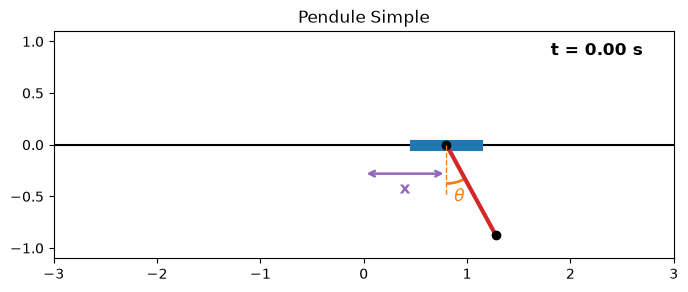

In [2]:
%matplotlib inline
single_initial_state = [.8, 0.0, .5, 0.0]
single_env_for_show = SinglePoleEnv(initial_state=single_initial_state, renderize=True, show_state=True)
single_env_for_show.render()

### Référence : contrôleur naïf

Ce contrôleur pousse dans le sens de l'écart angulaire par rapport à la verticale. Il ne tient compte ni de la vitesse du chariot ni de la vitesse angulaire. Mesurez ses performances : elles serviront de référence pour vos solutions NEAT.

In [3]:
def naive_single_controller(observation):
    theta = observation[2]
    angle_error = (theta - np.pi ) % (2.0 * np.pi) - np.pi
    return 2.0 if angle_error > 0.0 else -2.0

### Visualisation du controleur
Cette section permet d’observer le comportement du contrôleur naïf sur un exemple simple. Le but est de voir comment le système réagit visuellement avant de passer à l’entraînement avec NEAT.

Les commandes Matplotlib suivantes ont des usages différents :

- `%matplotlib inline` affiche les figures dans le notebook ;
- `%matplotlib tk` ouvre une fenêtre interactive séparée.

Pendant l’entraînement NEAT, il est préférable de désactiver le rendu. En effet, afficher une image à chaque étape de la simulation ralentit considérablement les calculs. Pour cette raison, on utilisera renderize=False (ou on ne précisera pas ce paramètre) pendant l’apprentissage. Le rendu graphique ne sera activé que pour observer une solution finale ou tester un cas particulier.

Pour visualiser le comportement d’un contrôleur, il suffit d’activer le rendu pendant la simulation. On peut alors observer le mouvement du chariot et des pendules, ainsi que leur stabilité. Cela permet de vérifier visuellement si le système reste en équilibre ou s’il s’écarte rapidement de la position souhaitée. Il est aussi possible de générer une animation complète de la simulation pour présenter les résultats de manière plus claire. Cette option donne un rendu plus lisible et est particulièrement utile dans un rapport ou dans un notebook. Elle demande toutefois un peu plus de temps avant l’affichage.


In [ ]:
def run_simulation(env, controller, duration=5.0):
    env_renderinG_parameter= env.renderize
    env.renderize = True
    observation = env.reset()
    num_steps = int(duration / env.dt)

    for _ in range(num_steps):
        action = controller(observation)
        observation, terminated = env.step(action)
        if terminated:
            break
    env.renderize = env_renderinG_parameter


In [ ]:
%matplotlib tk
single_initial_state = [0.0, 0.0, np.pi + 0.05, -0.5]

single_env = SinglePoleEnv(
    initial_state=single_initial_state,
    show_state=False,
    show_action=True
)

run_simulation(single_env,naive_single_controller,duration=10.0)
single_env.close()

In [ ]:
%matplotlib inline
plt.ioff()  # empêche l'affichage automatique de la figure
anim_env = SinglePoleEnv(initial_state=[0.0, 0.0, np.pi + 0.05, -0.5])
anim = animate_simulation(anim_env, naive_single_controller, duration=10.0, show_state=False, show_action=True)
html = HTML(anim.to_jshtml())
plt.close(anim.figure)  # évite qu'elle ne s'affiche dans une cellule ultérieure
plt.ion()  # réactive le mode interactif
html

## 3. Problème 2 : double pendule

L'observation devient `[x, x_dot, theta1, theta1_dot, theta2, theta2_dot]` : le chariot porte deux pendules en série. `theta1` et `theta2` décrivent les angles des deux pendules ; leurs dérivées sont leurs vitesses angulaires.

Les deux pendules doivent rester proches de la verticale haute (`theta1 = theta2 = pi`). La position initiale suit le même principe : `initial_state=[x, x_dot, theta1, theta1_dot, theta2, theta2_dot]`.

Observez la cellule suivante avec `show_state=True` : elle permet de relier les valeurs numériques à la configuration physique du système.

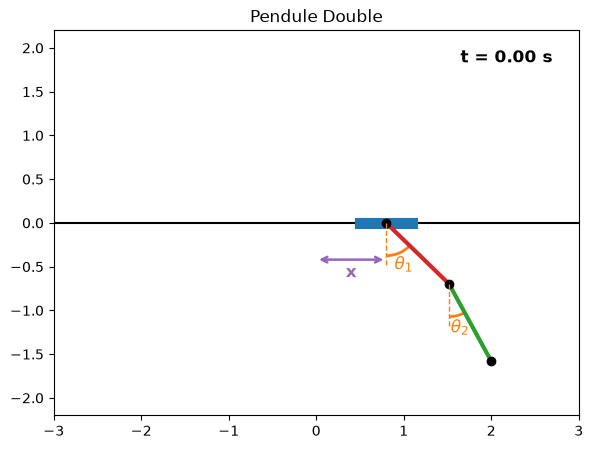

In [12]:
%matplotlib inline
double_initial_state = [0.8, 0.0, .8, 0.0, .5, 0.0]
double_env_for_show = DoublePoleEnv(
    initial_state=double_initial_state,
    renderize=True,
    show_state=True,
)

double_env_for_show.render()

### Référence : contrôleur naïf

Le contrôleur de référence applique une règle simple à l'erreur angulaire combinée des deux pendules. Il est volontairement limité : votre contrôleur NEAT devra apprendre une stratégie plus robuste.

In [10]:
def naive_double_controller(observation):
    theta1 = observation[2]
    theta2 = observation[4]
    error_1 = (theta1 - np.pi + np.pi) % (2.0 * np.pi) - np.pi
    error_2 = (theta2 - np.pi + np.pi) % (2.0 * np.pi) - np.pi
    return 0.0 if error_1 + error_2 > 0.0 else -0.0

### Simulation de référence

Cette simulation permet de comparer le comportement du contrôleur naïf sur le double pendule. Comme précédemment, le rendu sert uniquement à l'observation : pendant l'entraînement NEAT, désactivez-le pour conserver des évaluations rapides.

In [13]:
%matplotlib inline
plt.ioff()  # empêche l'affichage automatique de la figure
double_anim_env = DoublePoleEnv(initial_state=[0.0, 0.0, np.pi + 0.05, 0.0, np.pi - 0.05, 0.0])
double_anim = animate_simulation(double_anim_env, better_naive_double_controller, duration=10.0, show_state=False,show_action=True)
html=HTML(double_anim.to_jshtml())
plt.close(double_anim.figure)  # évite qu'elle ne s'affiche dans une cellule ultérieure
plt.ion()
html

## 4. Travail demandé

Pour chaque exercice, utilisez NEAT pour apprendre un contrôleur capable de maintenir les pendules en position verticale haute, ou de les remonter depuis une position basse. Vous devrez ensuite analyser de manière critique les résultats obtenus.

### Exercice 0 (à faire avant le TP 5) : contrôleurs naïfs pendule simple et double

Reprendre les contröleurs naïfs des pendules simple et double et en proposer de meilleurs.

### Exercice 1 : pendule simple, position haute fixée

Position initiale :

```python
initial_state = [0.0, 0.0, np.pi + 0.05, -0.5]
```

### Exercice 2 : pendule simple, position basse

Position initiale :

```python
initial_state = [0.0, 0.0, 0.0, 0.0]
```

### Exercice 3 : double pendule, position haute fixée

Position initiale :

```python
initial_state = [0.0, 0.0, np.pi + 0.05, 0.0, np.pi - 0.05, 0.0]
```

### Exercice 4 : double pendule, position basse

Position initiale :

```python
initial_state = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
```

## 5. Positions initiales aléatoires

Reprenez les quatre exercices avec des positions initiales choisies aléatoirement. Présentez et analysez les performances obtenues.

## 6. Barème sur 20

| Évaluation | Points |
| --- | ---: |
| Contrôleurs naïfs pendule simple et double (à faire avant le TP 5) | 2 |
| Pendule simple : position haute fixée | 5 |
| Pendule simple : position basse | 5 |
| Double pendule : position haute fixée | 2 |
| Double pendule : position basse | 2 |
| Positions initiales aléatoires | 2 |
| Organisation du groupe | 2 |
| Qualité du code, analyse et résultats | jusqu'à -10 |
| **Total** | **20** |

La qualité, la lisibilité et la réutilisabilité du code sont prises en compte. Aucune conclusion particulière sur NEAT n'est attendue ou secrètement privilégiée : seule l'expérience doit trancher. Vous pourrez défendre une réussite de NEAT, identifier ses limites ou conclure qu'il n'est pas approprié. La conclusion sera évaluée selon la solidité des arguments et la qualité des expériences réalisées.

### Bonus

Un bonus pourra être attribué pour résoudre un ou plusieurs problèmes avec une méthode de votre choix, sans obligation d'utiliser NEAT. Ce bonus ne remplace pas le travail demandé avec NEAT et ne constitue pas une autorisation de l'éviter : NEAT doit être implémenté et étudié pour obtenir les points du barème principal. Une résolution parfaite avec une autre méthode, sans travail sur NEAT, ne pourra donc pas atteindre la moyenne à elle seule.

Pour être pris en compte, le bonus devra présenter la méthode choisie, justifier les choix réalisés, fournir un contrôleur facilement évaluable par l'enseignant et comparer ses performances avec celles obtenues avec NEAT.